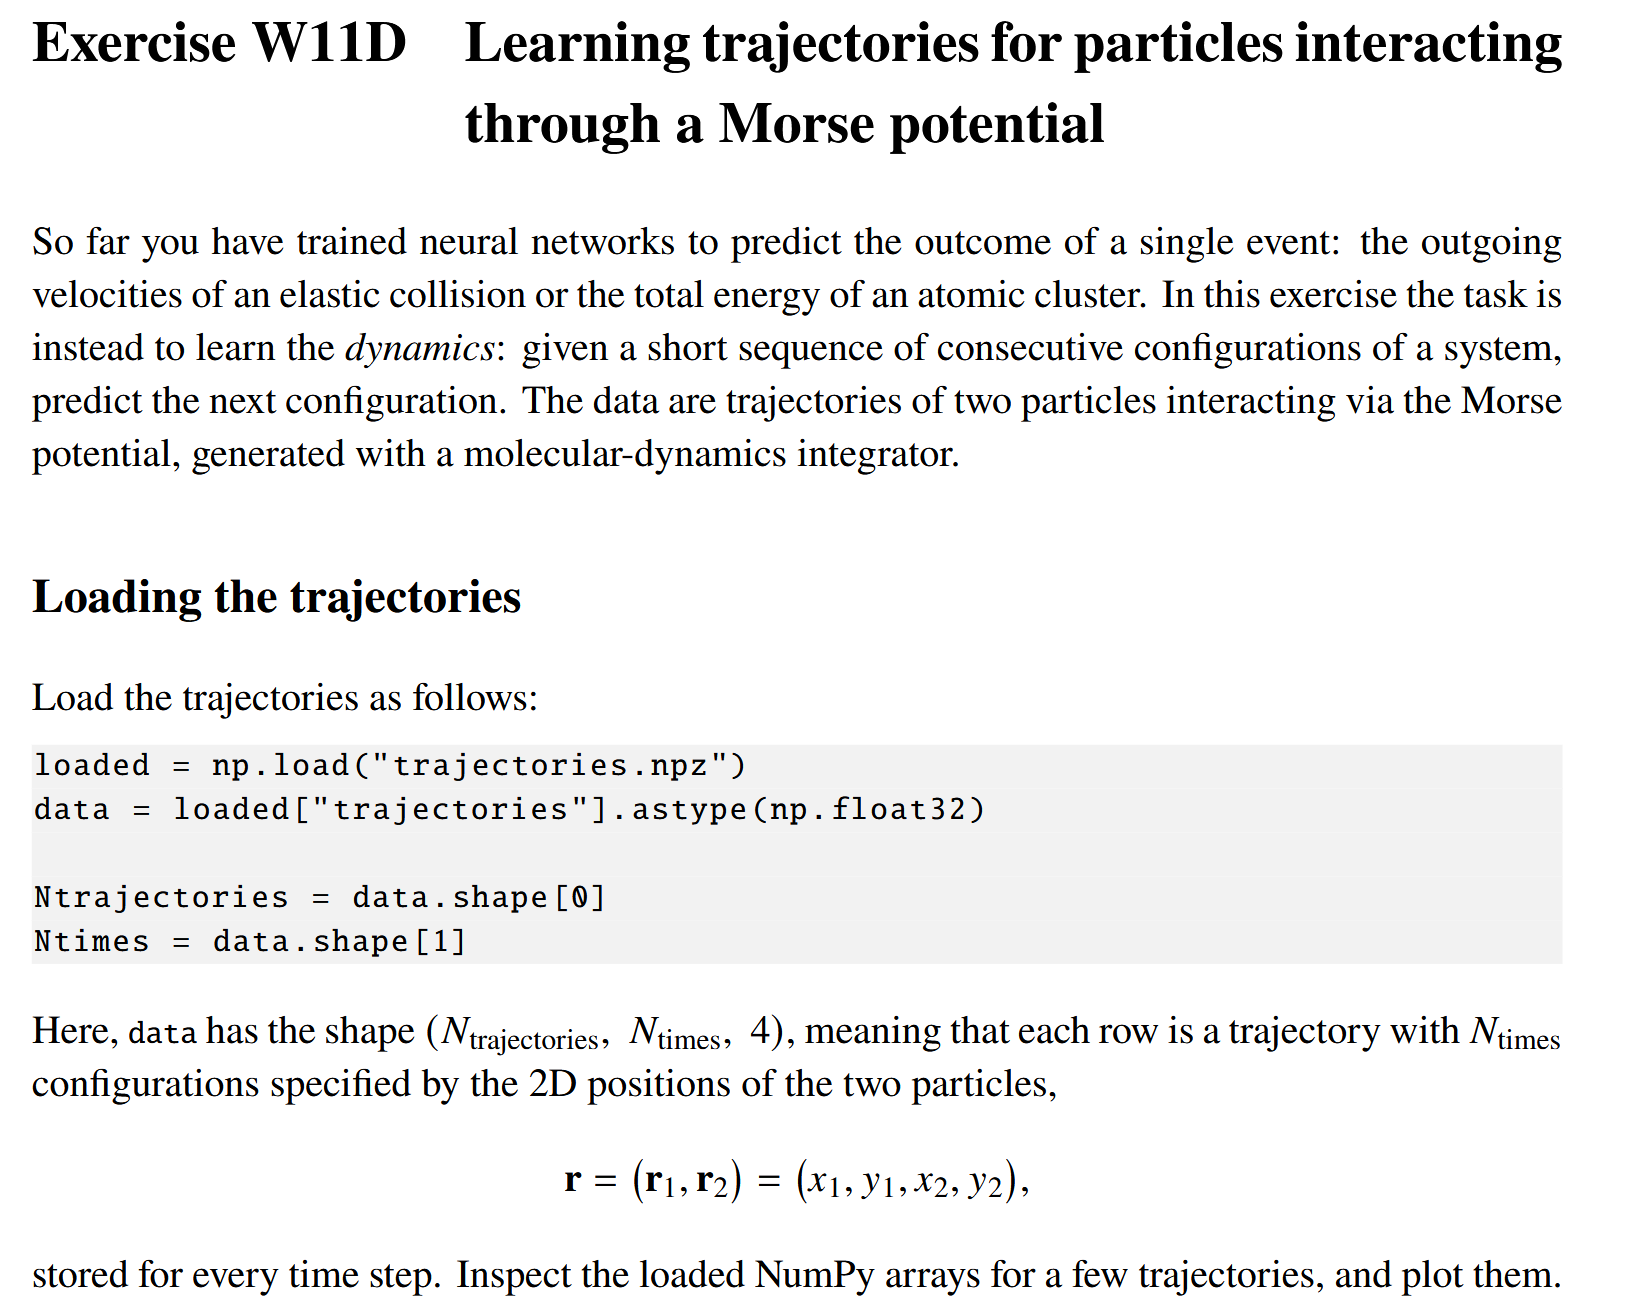

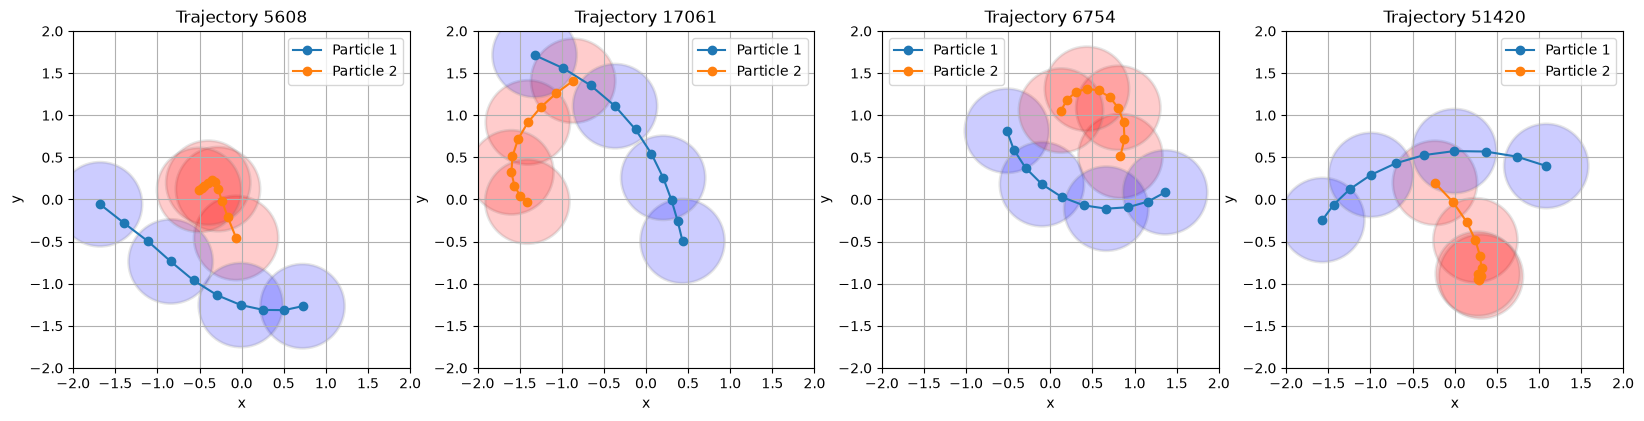

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
import torch
import torch.nn as nn
import torch.optim as optim

loaded = np.load('trajectories.npz')
data = loaded['trajectories'].astype(np.float32)

Ntraj = data.shape[0]
Ntimes = data.shape[1]

def plot_trajectory(ax, idx, data):
    traj = data[idx]
    
    x1 = traj[:, 0]
    y1 = traj[:, 1]
    
    x2 = traj[:, 2]
    y2 = traj[:, 3]
    
    ax.plot(x1, y1, 'o-', label='Particle 1')
    ax.plot(x2, y2, 'o-', label='Particle 2')

    radius = 0.5
    
    step = max(1, len(traj) // 3)
    indices = list(range(0, len(traj), step))
    if indices[-1] != len(traj) - 1:
        indices[-1] = len(traj) - 1
        
    for i in indices:
        c1 = Circle((x1[i], y1[i]), radius, facecolor='blue', edgecolor='gray', linewidth=2, alpha=0.2, zorder=1)
        c2 = Circle((x2[i], y2[i]), radius, facecolor='red', edgecolor='gray', linewidth=2, alpha=0.2, zorder=1)
        ax.add_patch(c1)
        ax.add_patch(c2)

    ax.set_title(f'Trajectory {idx}')
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_xlim(-2, 2)
    ax.set_ylim(-2, 2)
    ax.legend()
    ax.set_aspect('equal')
    ax.grid(True)

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

for ax in axes:
    idx = np.random.choice(range(Ntraj))
    plot_trajectory(ax, idx, data)
    

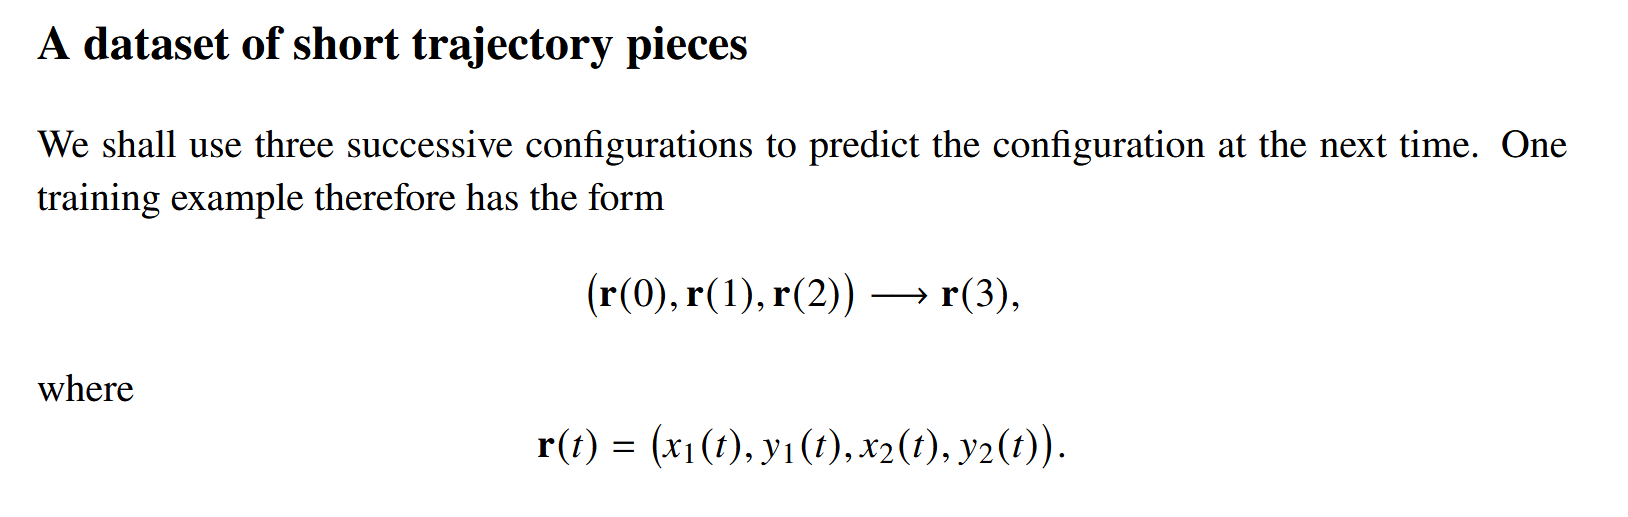
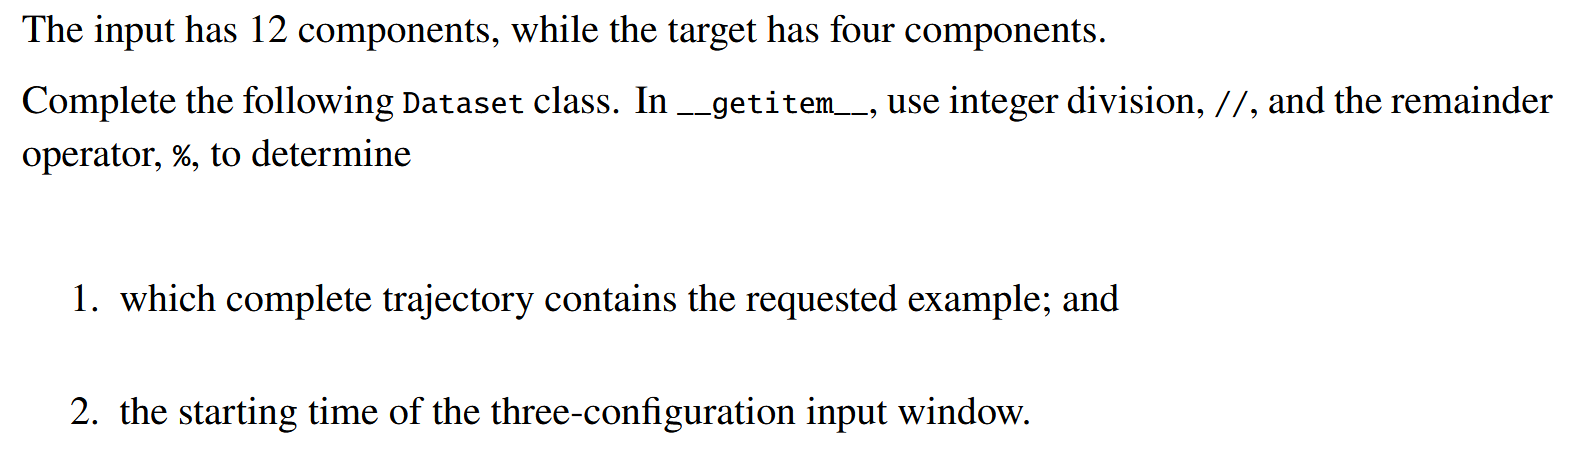
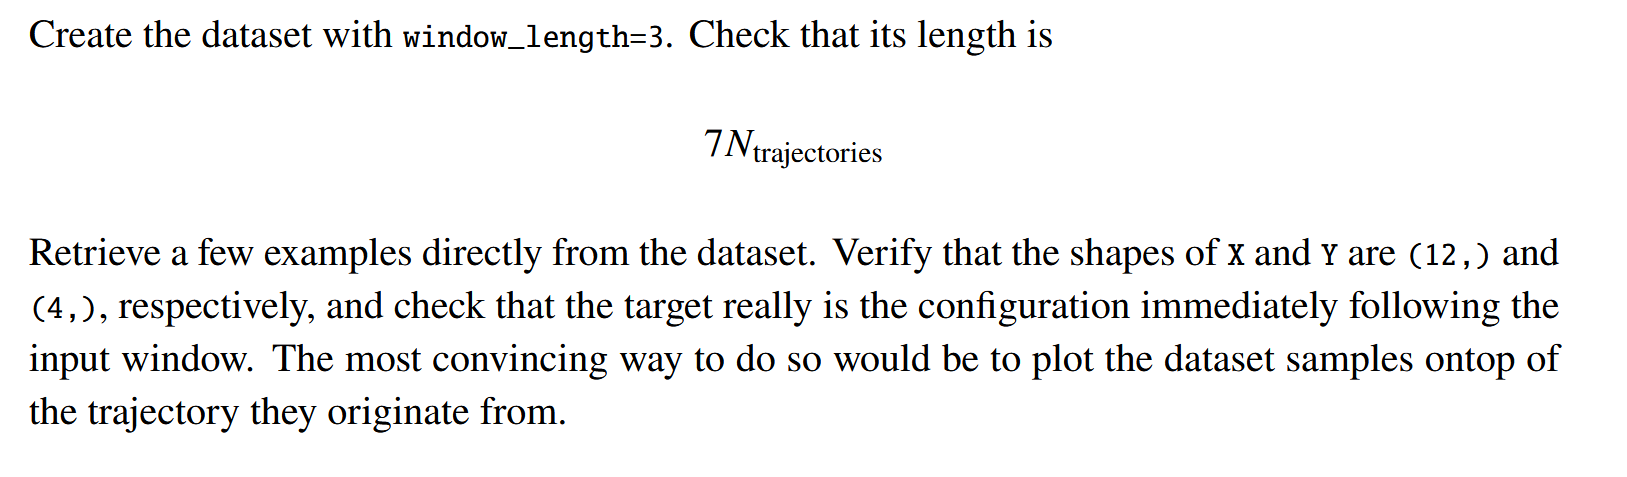

Dataset length: 440986
Expected (7 * N_trajectories): 440986
Shape of X: torch.Size([12])
Shape of Y: torch.Size([4])


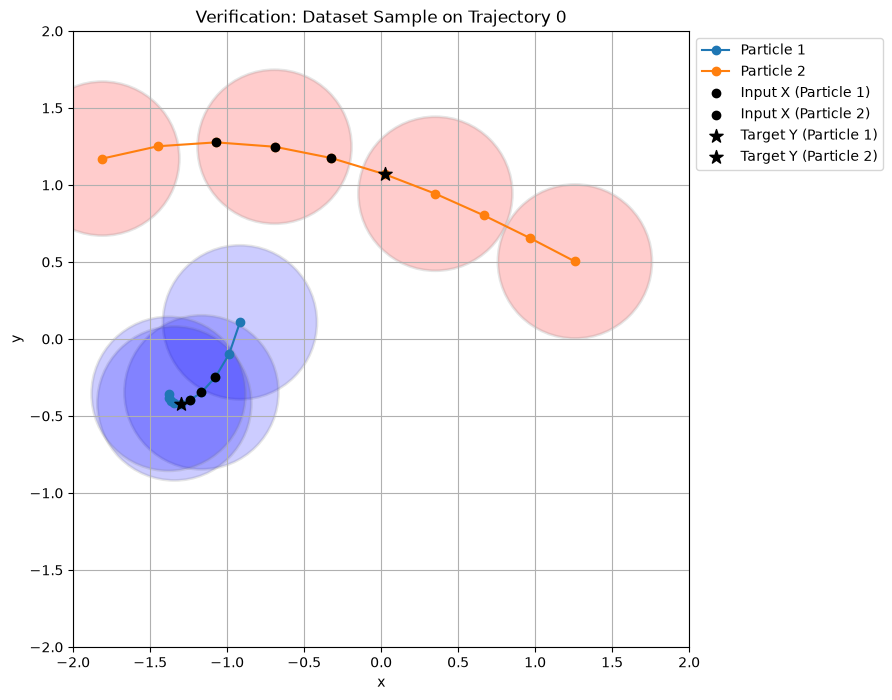

In [2]:
from torch.utils.data import Dataset, DataLoader

class TrajectoryDataset(Dataset):
    def __init__(self, trajectories, window_length=3):
        self.trajectories = torch.as_tensor(trajectories, dtype=torch.float32)
        self.window_length = window_length
        self.Ntrajectories = self.trajectories.shape[0]
        self.Ntimes = self.trajectories.shape[1]
        self.Npieces_per_trajectory = self.Ntimes - self.window_length

    def __len__(self):
        return self.Ntrajectories * self.Npieces_per_trajectory

    def __getitem__(self, index):
        trajectory_index = index // self.Npieces_per_trajectory 
        
        start = index % self.Npieces_per_trajectory 
        stop = start + self.window_length
        
        trajectory = self.trajectories[trajectory_index] 
        
        X = trajectory[start:stop].reshape(-1) 
        Y = trajectory[stop]                   
        
        return X, Y

dataset = TrajectoryDataset(data, window_length=3)

expected_length = 7 * dataset.Ntrajectories
print(f"Dataset length: {len(dataset)}")
print(f"Expected (7 * N_trajectories): {expected_length}")

X, Y = dataset[0]
print(f"Shape of X: {X.shape}")
print(f"Shape of Y: {Y.shape}")

fig, ax = plt.subplots(figsize=(8, 8))

trajectory_idx = 0
piece_within_trajectory = 2 
dataset_idx = trajectory_idx * 7 + piece_within_trajectory

plot_trajectory(ax, trajectory_idx, data)

X_sample, Y_sample = dataset[dataset_idx]
X_reshaped = X_sample.view(3, 4).numpy()
Y_np = Y_sample.numpy()

ax.scatter(X_reshaped[:, 0], X_reshaped[:, 1], color='black', zorder=5, label='Input X (Particle 1)')
ax.scatter(X_reshaped[:, 2], X_reshaped[:, 3], color='black', zorder=5, label='Input X (Particle 2)')

ax.scatter(Y_np[0], Y_np[1], color='black', s=100, marker='*', zorder=6, label='Target Y (Particle 1)')
ax.scatter(Y_np[2], Y_np[3], color='black', s=100, marker='*', zorder=6, label='Target Y (Particle 2)')

ax.set_title(f"Verification: Dataset Sample on Trajectory {trajectory_idx}")
handles, labels = ax.get_legend_handles_labels()
unique_labels = dict(zip(labels, handles))
ax.legend(unique_labels.values(), unique_labels.keys(), loc='upper left', bbox_to_anchor=(1, 1))

plt.show()


* **Shuffling mechanics:** When a PyTorch `DataLoader` applies shuffling, it randomizes the `index` values passed to the `__getitem__` method. This changes the order in which the short trajectory pieces are presented to the model during training, ensuring the optimizer sees a diverse mix of states. However, this shuffling does not destroy the internal time ordering of the input window because `__getitem__` mathematically maps each single index to a fixed, contiguous slice (`[start:stop]`) of the original trajectory, ensuring the three configurations within `X` and its corresponding target `Y` remain perfectly sequential.


* **First 7 examples:** Because the `DataLoader` is drawing random indices from the entire pool of generated pieces, the first 7 pieces it serves will be sampled from randomly distributed trajectories across the entire dataset. They will generally no longer belong to the first original trajectory as they would in an unshuffled, sequential iteration.


* **Dividing complete trajectories:** A complete trajectory is composed of several strongly related short trajectory pieces. Because these pieces represent continuous physical motion, adjacent pieces are nearly identical. Therefore, if you were to randomly divide the dataset *after* constructing the short pieces, highly correlated pieces from the same original trajectory could end up in both the training set and the test set.


* **Optimistic errors:** If pieces from the same continuous trajectory leak across data splits, the model can simply memorize the specific motion patterns of the training pieces and apply them to the nearly identical test pieces. This data leakage results in a severely overly optimistic validation or test error that does not accurately reflect the model's ability to generalize to entirely new, unseen physical trajectories. Therefore, the split must happen at the level of complete trajectories *before* the three-step pieces are constructed.

In [3]:
train_traj = data[:800]
val_traj = data[800:900]
test_traj = data[900:1000]

train_data = TrajectoryDataset(train_traj)
val_data = TrajectoryDataset(val_traj)
test_data = TrajectoryDataset(test_traj)

train_loader = DataLoader(train_data, batch_size=100, shuffle=True)
val_loader = DataLoader(val_data, batch_size=len(val_traj), shuffle=False)
test_loader = DataLoader(test_data, batch_size=len(test_data), shuffle=False)

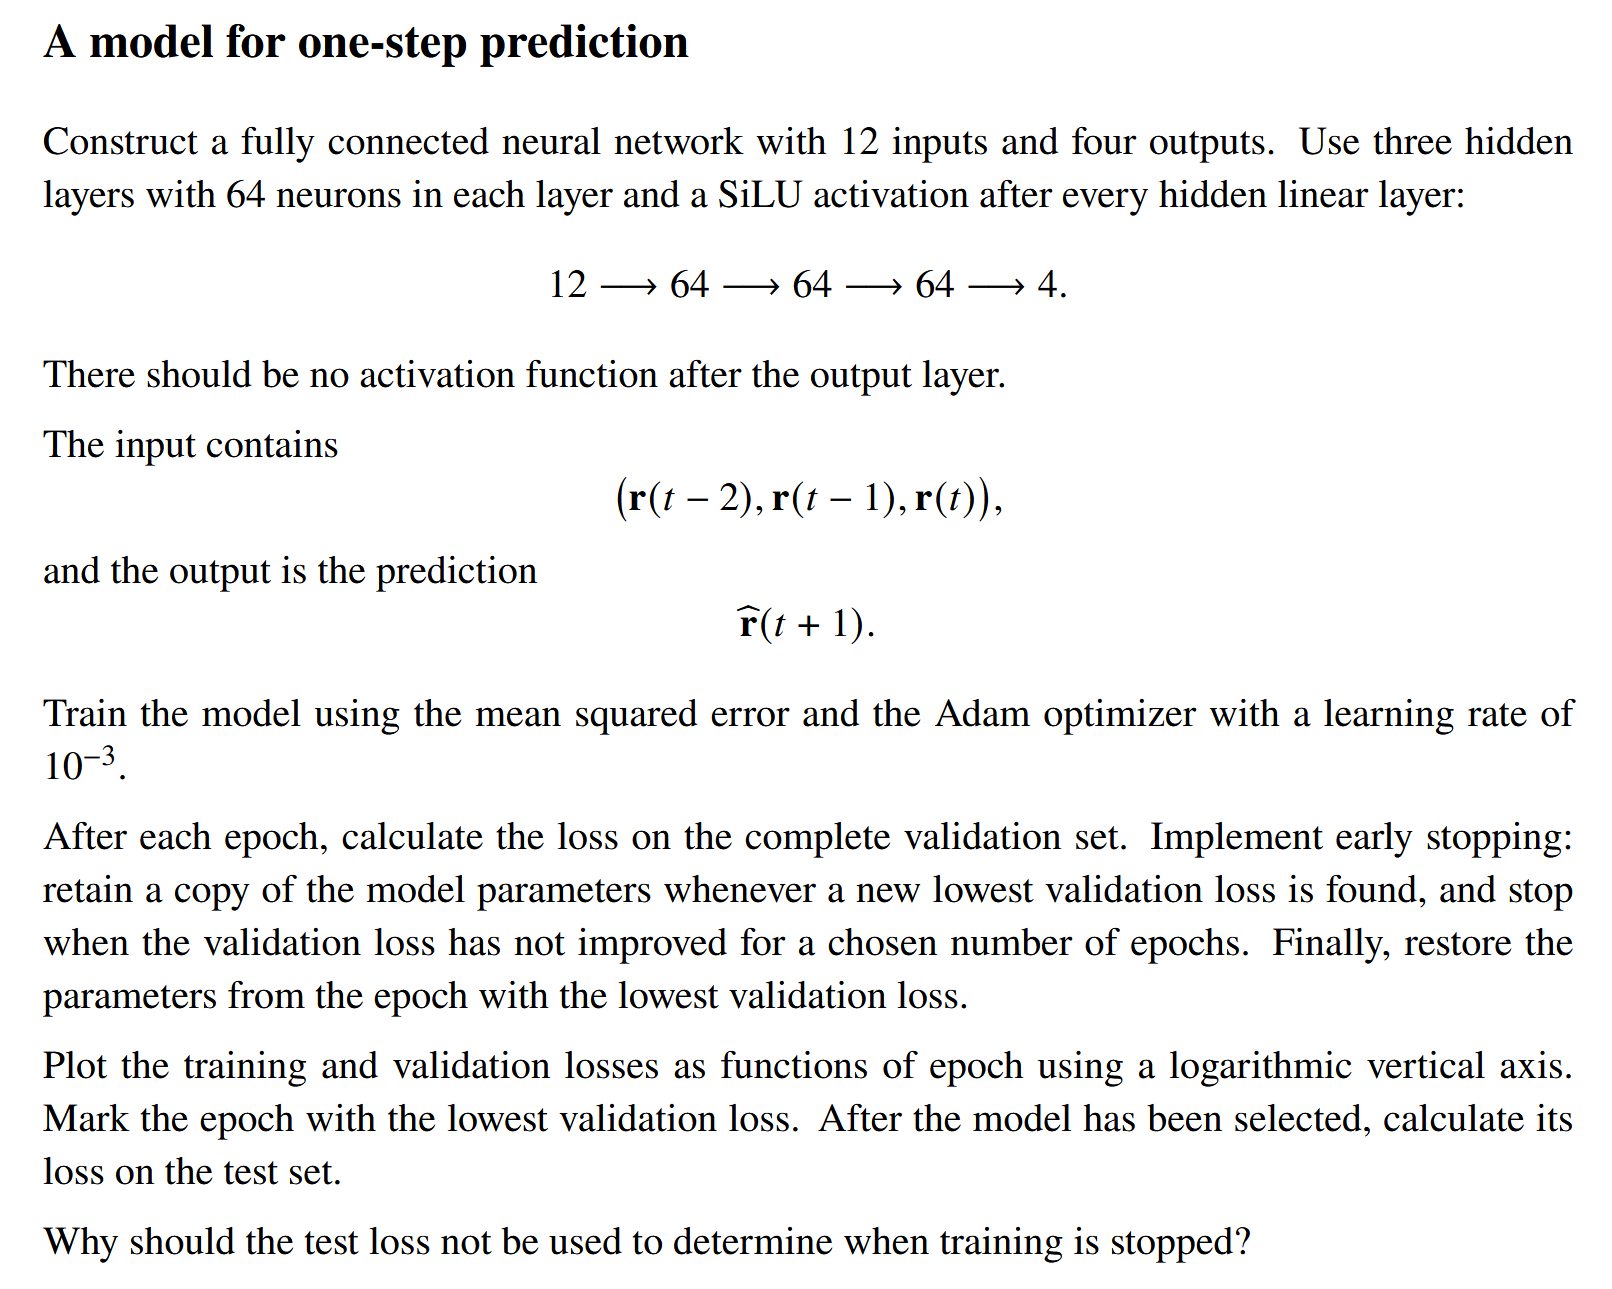

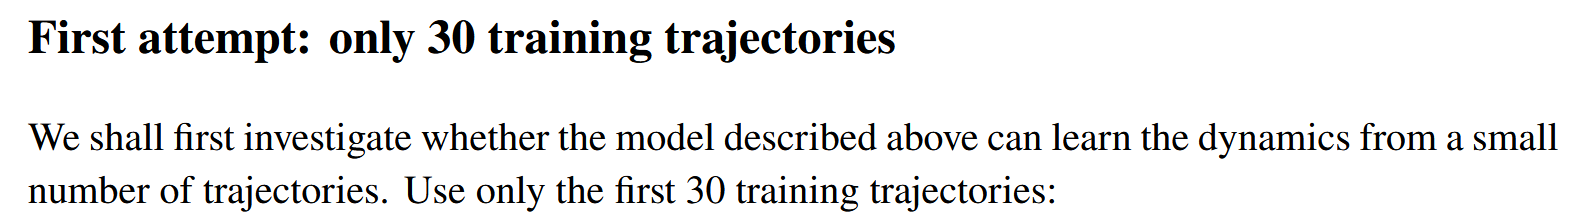
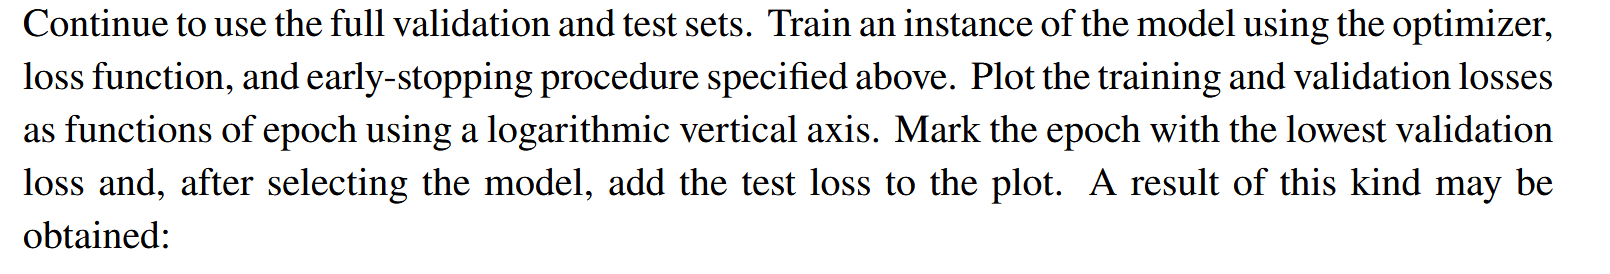
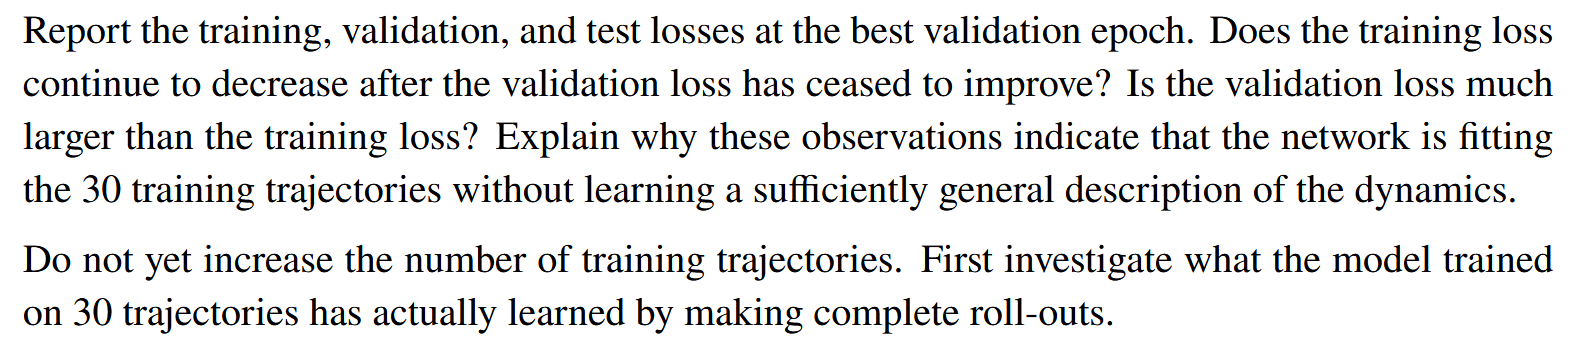

Epoch: 1 - Validation Loss: 0.677375887121473
Epoch: 2 - Validation Loss: 0.5755609103611538
Epoch: 3 - Validation Loss: 0.476594294820513
Epoch: 4 - Validation Loss: 0.38244631034987314
Epoch: 5 - Validation Loss: 0.30428737827709745
Epoch: 6 - Validation Loss: 0.24637318508965628
Epoch: 7 - Validation Loss: 0.20696696426187242
Epoch: 8 - Validation Loss: 0.18090161042554037
Epoch: 9 - Validation Loss: 0.1670916016612734
Epoch: 10 - Validation Loss: 0.15983769510473525
Epoch: 11 - Validation Loss: 0.1560016487325941
Epoch: 12 - Validation Loss: 0.15132747909852437
Epoch: 13 - Validation Loss: 0.14599345305136271
Epoch: 14 - Validation Loss: 0.1394795168723379
Epoch: 15 - Validation Loss: 0.13299904550824845
Epoch: 16 - Validation Loss: 0.1295111690248762
Epoch: 17 - Validation Loss: 0.125573992729187
Epoch: 18 - Validation Loss: 0.12125637595142637
Epoch: 19 - Validation Loss: 0.1166885963508061
Epoch: 20 - Validation Loss: 0.11045383236237935
Epoch: 21 - Validation Loss: 0.1071840790

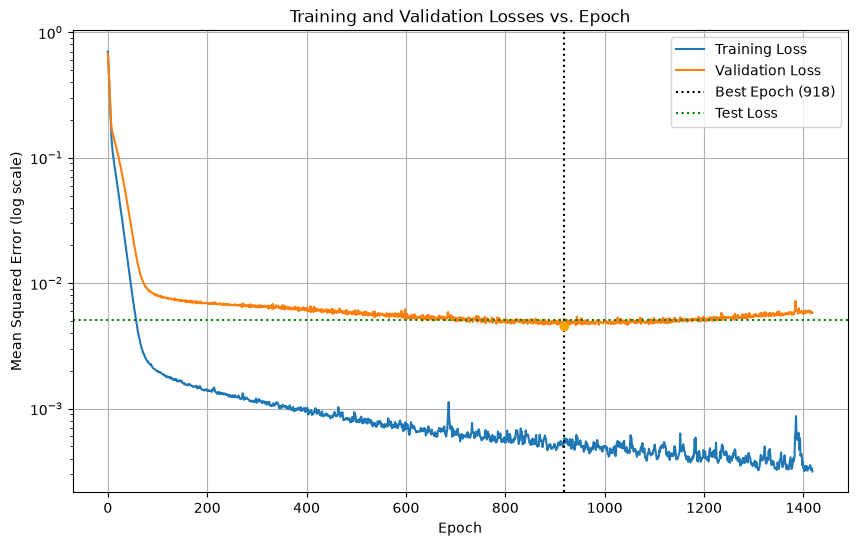

In [4]:
from models import *

small_train_loader = DataLoader(TrajectoryDataset(train_traj[0:30]), 
                                batch_size=30, 
                                shuffle=True)

model = XDLinearModel(in_dim=12, out_dim=4, hidden=64, layers=2)
trained_model, history = fit_model(model=model, 
                                    train_loader=small_train_loader, 
                                    val_loader=val_loader, 
                                    test_loader=test_loader, 
                                    epochs=5000, 
                                    patience=500)

train_losses = history['train_loss']
val_losses = history['val_loss']
test_loss = history['test_loss']

best_val_loss = min(val_losses)
best_epoch_idx = val_losses.index(best_val_loss)

plt.figure(figsize=(10, 6))
plt.plot(train_losses, label='Training Loss')
plt.plot(val_losses, label='Validation Loss')
plt.axvline(x=best_epoch_idx, color='k', linestyle=':', label=f'Best Epoch ({best_epoch_idx})')
plt.axhline(y=test_loss, color='g', linestyle=':', label='Test Loss')
plt.scatter([best_epoch_idx], [best_val_loss], color='orange', zorder=5)
plt.yscale('log')
plt.title('Training and Validation Losses vs. Epoch')
plt.xlabel('Epoch')
plt.ylabel('Mean Squared Error (log scale)')
plt.legend()
plt.grid(True)
plt.show()

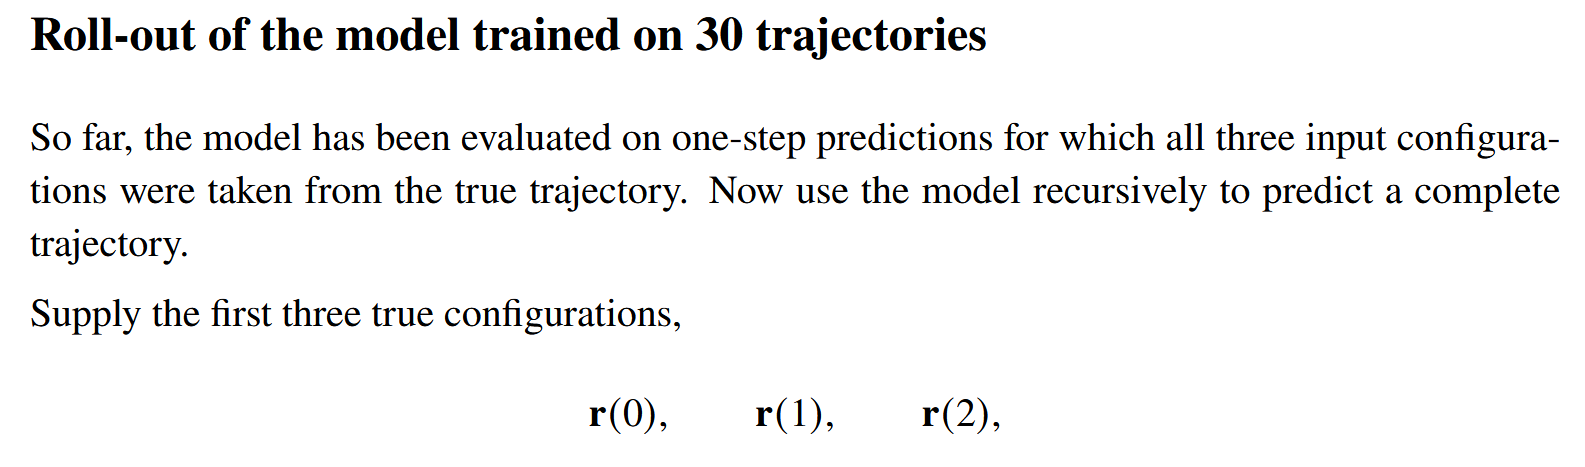
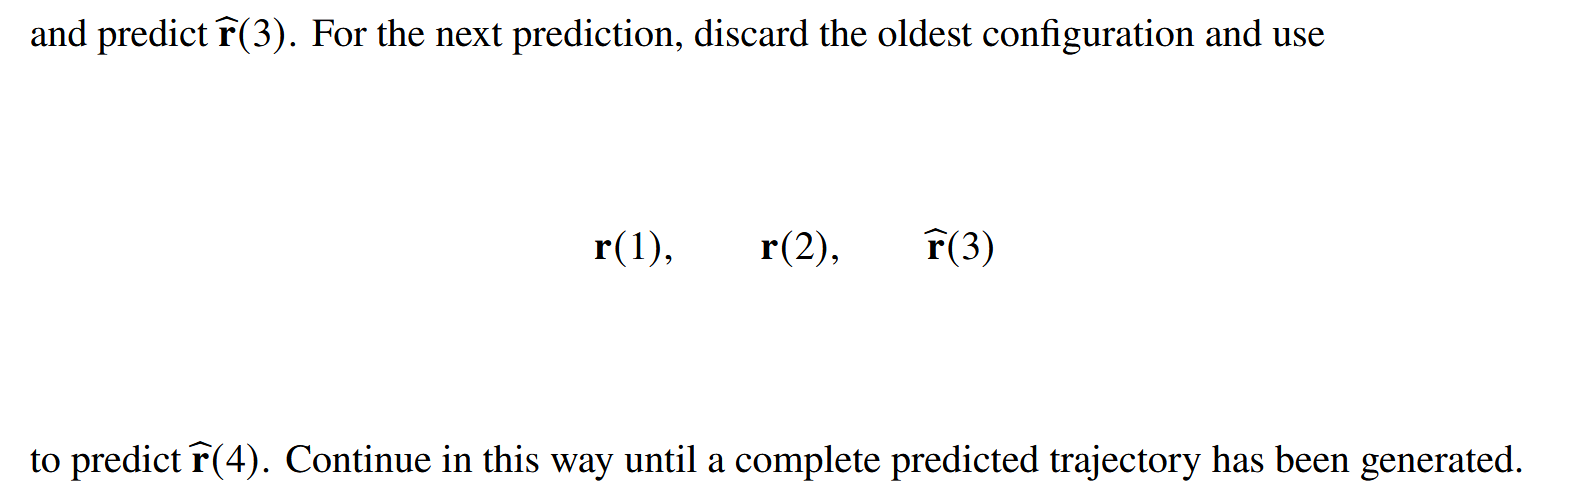
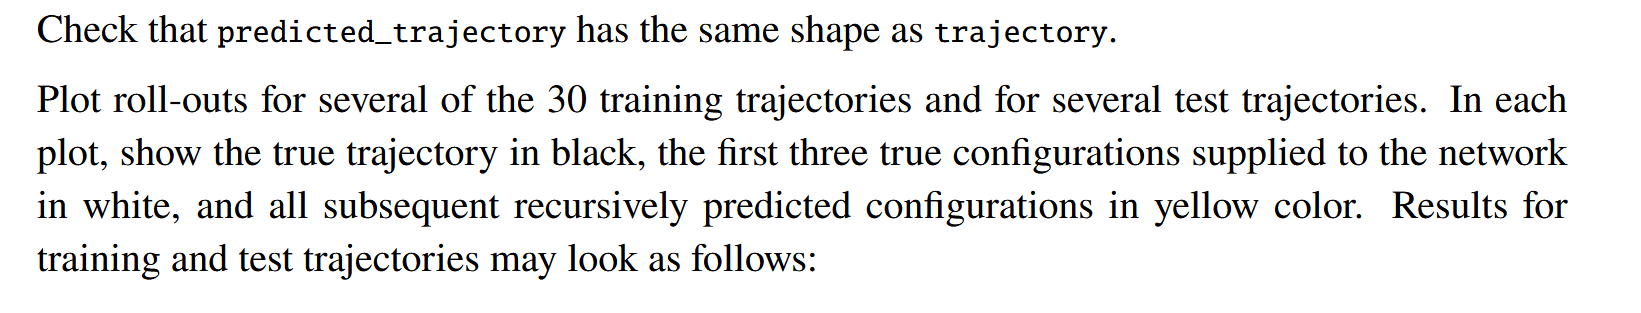

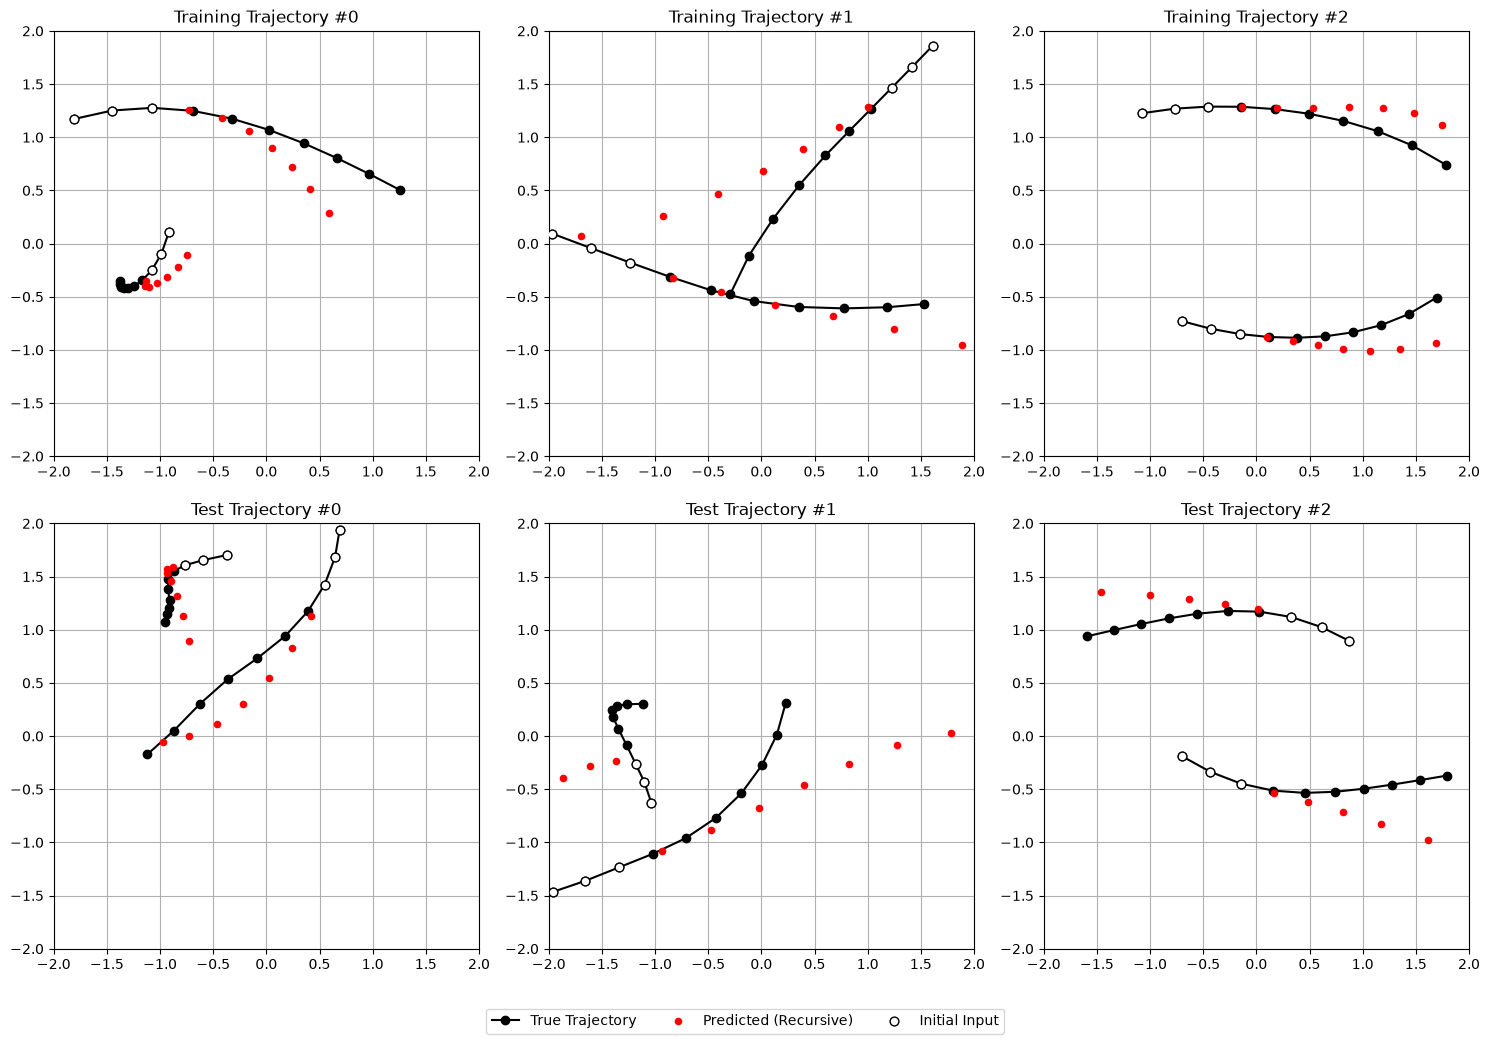

In [5]:
def rollout(model, trajectory):
    """Predict a trajectory from its first three configurations."""
    trajectory = torch.as_tensor(trajectory, dtype=torch.float32)
    window = trajectory[:3]
    prediction = [r for r in window] 

    with torch.no_grad():
        for _ in range(3, len(trajectory)):
            x = window.reshape(1, 12)
            r_new = model(x)[0] 

            prediction.append(r_new)

            window = torch.cat(
                (window[1:], r_new[None, :]),
                dim=0,
            )

    return torch.stack(prediction)

def plot_rollout(ax, true_traj, pred_traj, title):
    true_x1, true_y1 = true_traj[:, 0], true_traj[:, 1]
    true_x2, true_y2 = true_traj[:, 2], true_traj[:, 3]
    
    pred_x1, pred_y1 = pred_traj[:, 0].numpy(), pred_traj[:, 1].numpy()
    pred_x2, pred_y2 = pred_traj[:, 2].numpy(), pred_traj[:, 3].numpy()
    
    ax.plot(true_x1, true_y1, 'o-', color='black', linewidth=1.5, label='True Trajectory')
    ax.plot(true_x2, true_y2, 'o-', color='black', linewidth=1.5)
    
    ax.scatter(pred_x1[3:], pred_y1[3:], color='red', s=20, zorder=3, label='Predicted (Recursive)')
    ax.scatter(pred_x2[3:], pred_y2[3:], color='red', s=20, zorder=3)
    
    ax.scatter(true_x1[:3], true_y1[:3], color='white', edgecolor='black', s=40, zorder=4, label='Initial Input')
    ax.scatter(true_x2[:3], true_y2[:3], color='white', edgecolor='black', s=40, zorder=4)
    
    ax.set_title(title)
    ax.set_xlim(-2, 2)
    ax.set_ylim(-2, 2)
    ax.set_aspect('equal')
    ax.grid(True)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for i in range(3):
    true_traj = train_data.trajectories[i]
    pred_traj = rollout(trained_model, true_traj)
    
    assert pred_traj.shape == true_traj.shape, f"Shape mismatch: {pred_traj.shape} != {true_traj.shape}"
    
    plot_rollout(axes[i], true_traj, pred_traj, title=f"Training Trajectory #{i}")

for i in range(3):
    idx = i
    true_traj = test_data.trajectories[idx]
    pred_traj = rollout(trained_model, true_traj)
    
    assert pred_traj.shape == true_traj.shape, f"Shape mismatch: {pred_traj.shape} != {true_traj.shape}"
    
    plot_rollout(axes[i+3], true_traj, pred_traj, title=f"Test Trajectory #{idx}")

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.05))
plt.tight_layout()
plt.show()

Epoch: 1 - Validation Loss: 0.14816827859197343
Epoch: 2 - Validation Loss: 0.09902004152536392
Epoch: 3 - Validation Loss: 0.055809961897986274
Epoch: 4 - Validation Loss: 0.021818580638085092
Epoch: 5 - Validation Loss: 0.008540071547031403
Epoch: 6 - Validation Loss: 0.0064060310167925695
Epoch: 7 - Validation Loss: 0.00579168155257191
Epoch: 8 - Validation Loss: 0.005479882404740367
Epoch: 9 - Validation Loss: 0.005240770988166332
Epoch: 10 - Validation Loss: 0.004993480098034654
Epoch: 11 - Validation Loss: 0.00486173400921481
Epoch: 12 - Validation Loss: 0.004705249897337386
Epoch: 13 - Validation Loss: 0.004671511905533927
Epoch: 14 - Validation Loss: 0.004493806577686753
Epoch: 15 - Validation Loss: 0.004434771802542465
Epoch: 16 - Validation Loss: 0.00430208640838308
Epoch: 17 - Validation Loss: 0.004230176664090582
Epoch: 18 - Validation Loss: 0.004143660721768226
Epoch: 19 - Validation Loss: 0.00399549473409674
Epoch: 20 - Validation Loss: 0.003963258183960404
Epoch: 21 - Va

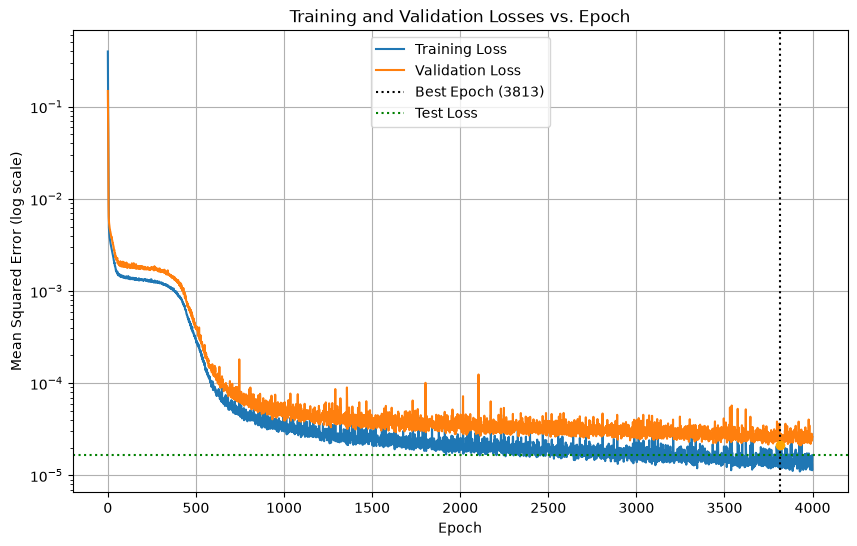

In [6]:
model = XDLinearModel(in_dim=12, out_dim=4, hidden=64, layers=2)
trained_model, history = fit_model(model=model, 
                                    train_loader=train_loader, 
                                    val_loader=val_loader, 
                                    test_loader=test_loader,
                                    epochs=4000, 
                                    patience=500)

train_losses = history['train_loss']
val_losses = history['val_loss']
test_loss = history['test_loss']

best_val_loss = min(val_losses)
best_epoch_idx = val_losses.index(best_val_loss)

plt.figure(figsize=(10, 6))
plt.plot(train_losses, label='Training Loss')
plt.plot(val_losses, label='Validation Loss')
plt.axvline(x=best_epoch_idx, color='k', linestyle=':', label=f'Best Epoch ({best_epoch_idx})')
plt.axhline(y=test_loss, color='g', linestyle=':', label='Test Loss')
plt.scatter([best_epoch_idx], [best_val_loss], color='orange', zorder=5)
plt.yscale('log')
plt.title('Training and Validation Losses vs. Epoch')
plt.xlabel('Epoch')
plt.ylabel('Mean Squared Error (log scale)')
plt.legend()
plt.grid(True)
plt.show()

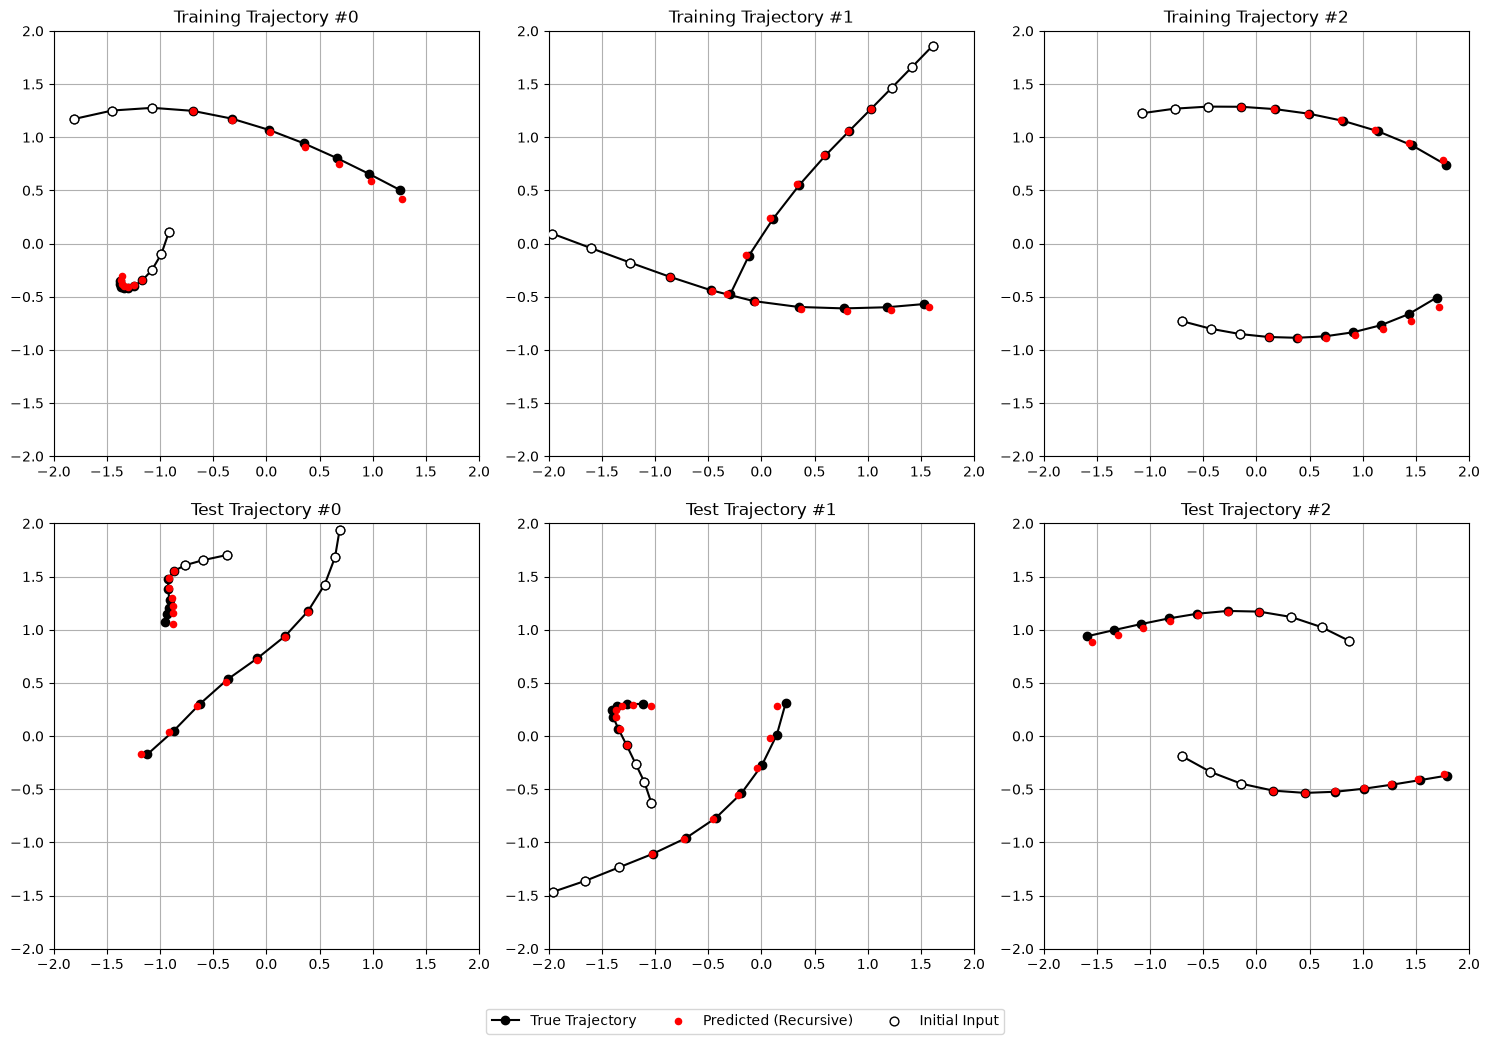

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for i in range(3):
    true_traj = train_data.trajectories[i]
    pred_traj = rollout(trained_model, true_traj)
    
    assert pred_traj.shape == true_traj.shape, f"Shape mismatch: {pred_traj.shape} != {true_traj.shape}"
    
    plot_rollout(axes[i], true_traj, pred_traj, title=f"Training Trajectory #{i}")

for i in range(3):
    idx = i
    true_traj = test_data.trajectories[idx]
    pred_traj = rollout(trained_model, true_traj)
    
    assert pred_traj.shape == true_traj.shape, f"Shape mismatch: {pred_traj.shape} != {true_traj.shape}"
    
    plot_rollout(axes[i+3], true_traj, pred_traj, title=f"Test Trajectory #{idx}")

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.05))
plt.tight_layout()
plt.show()

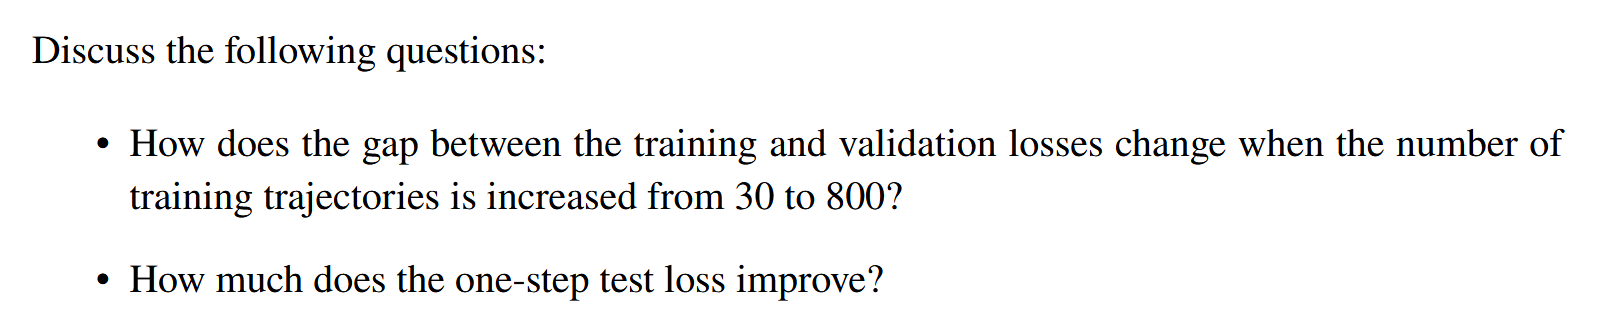
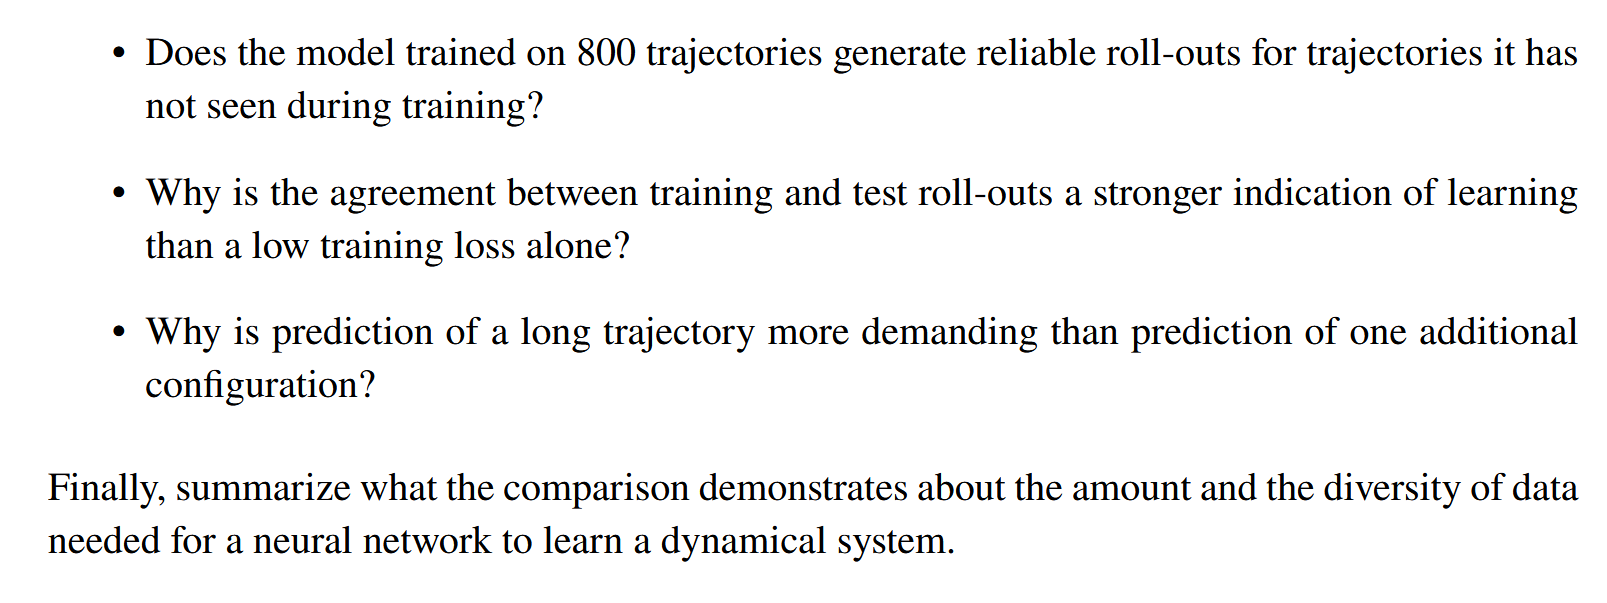

* **How the gap between training and validation losses changes:** When the number of training trajectories is increased from 30 to 800, the gap between the training and validation losses shrinks significantly. A model trained on only 30 trajectories will easily memorize the small dataset (achieving very low training loss) but will fail to generalize (resulting in high validation loss). Increasing the dataset to 800 trajectories provides a much broader representation of the underlying physics, forcing the model to learn the actual rules of the dynamical system rather than memorizing specific examples, which causes the validation loss to drop closer to the training loss.


* **Improvement in one-step test loss:** The one-step test loss improves dramatically—often by several orders of magnitude—when moving from 30 to 800 trajectories. The massive increase in diverse training data allows the network to interpolate much more accurately when presented with unseen one-step configurations.


* **Reliability of roll-outs on unseen trajectories:** Yes, the model trained on 800 trajectories generates highly reliable roll-outs for trajectories it has never seen before. Because it has learned the generalized physical rules governing the particle interactions rather than memorizing a few specific paths, it can recursively predict long, accurate sequences even from novel starting conditions.


* **Agreement between roll-outs vs. low training loss:** The agreement between training and test roll-outs is a much stronger indication of learning because a low training loss only proves the model can memorize the data it has already seen. Consistent performance across both seen and unseen roll-outs proves that the model has internalized the true underlying dynamics of the system and can generalize those rules to entirely new scenarios.


* **Why predicting a long trajectory is more demanding:** Predicting a long trajectory is much more demanding than predicting one additional configuration because it requires recursive prediction. In a one-step prediction, the model is always fed ground-truth data. In a long roll-out, the model's own predictions become its future inputs. Any small error made in the first few steps will be compounded and amplified exponentially over time, causing a poorly trained model to rapidly diverge from the true physical path.



**Summary:**
This comparison demonstrates that learning the physics of a dynamical system requires a massive amount of highly diverse data. A small dataset (like 30 trajectories) allows the network to cheat by memorizing specific paths, leading to catastrophic failure during recursive roll-outs on unseen data. Providing a vast and diverse dataset (800 trajectories) prevents memorization and forces the neural network to approximate the true underlying differential equations governing the particles, which is the only way to achieve stable, accurate, long-term predictions.